In [26]:
import random
from pathlib import Path
import torchaudio
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score
from tqdm.auto import tqdm   
from config import CHILD, CHILD_AFR_SADILAR, ADULT_NCHLT, NOISY_DIR, RESULTS_DIR

tqdm.pandas()    
#Fixed seeds and the 16 kHz rate MMS expects
random.seed(42)
np.random.seed(42)
SAMPLE_RATE = 16000

In [27]:
from transformers import Wav2Vec2ForSequenceClassification, AutoFeatureExtractor

#Facebook LLM ID
lid_model_id = "facebook/mms-lid-126"

feature_extractor = AutoFeatureExtractor.from_pretrained(lid_model_id)

#wav2vec 2.0 encoder with a classification head over 126 languages
model = Wav2Vec2ForSequenceClassification.from_pretrained(lid_model_id)

device = "cpu"

#eval() switches off dropout so the embeddings are repeatable
lid_model = model.to(device).eval()
print(f"Model loaded on {device}")

Model loaded on cpu


In [28]:
#Takes n_total utterances spread as evenly as possible over the speakers
def balanced_subsample(df, n_total, group="speaker", seed=42):
    # rank utterances within each speaker (0,1,2,...) after shuffling,
    # then take the lowest ranks first -> one per speaker before a second, etc.
    shuffled = df.sample(frac=1, random_state=seed)
    rank = shuffled.groupby(group).cumcount()
    return (shuffled.assign(_r=rank.values)
                    .sort_values(["_r", group])
                    .head(n_total)
                    .drop(columns="_r")
                    .reset_index(drop=True))

In [29]:
#LOADING CHILD AFR DATASET:
CHILD_MANIFEST_AFR, CHILD_AUDIO_DIR_AFR = CHILD["afr"]

afr_child_df = pd.read_csv(CHILD_MANIFEST_AFR)
afr_child_df["path"] = afr_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_AFR / f)
afr_child_df["true_lang"] = "afr"   
print(f"Loaded {len(afr_child_df)} AFR audio segments.") 

#Cut every language down to 10 085 utterances, the size of the Sesotho sa Leboa set
afr_child_df = balanced_subsample(afr_child_df, n_total=10085)  
print(afr_child_df["speaker"].value_counts().describe())
print(f"Afrikaans Child files subsampled : {len(afr_child_df)} / {len(afr_child_df)}")
afr_child_df["true_lang"] = "afr"

total_s = afr_child_df["duration_s"].sum()
print(f"Total duration of Afrikaans child dataset (subsampled): {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 13990 AFR audio segments.
count    154.000000
mean      65.487013
std       13.191519
min       26.000000
25%       60.000000
50%       73.000000
75%       74.000000
max       74.000000
Name: count, dtype: float64
Afrikaans Child files subsampled : 10085 / 10085
Total duration of Afrikaans child dataset (subsampled): 13779.49 seconds, or 229.66 minutes, or 3.83 hours.


In [30]:
#LOADING CHILD ENGLISH DATASET : 
CHILD_MANIFEST_ENG, CHILD_AUDIO_DIR_ENG = CHILD["eng"]

eng_child_df = pd.read_csv(CHILD_MANIFEST_ENG)
#Each session has its own folder and the files are whole recordings, not cut segments
eng_child_df["path"] = eng_child_df.apply(lambda r: CHILD_AUDIO_DIR_ENG / r["session"] / r["filename"], axis=1)
#Speech duration from the time stamps, only used to report the hours
eng_child_df["duration_s"] = (eng_child_df["end_ms"] - eng_child_df["start_ms"]) / 1000.0

print(f"Loaded {len(eng_child_df)} ENG audio segments")

#No speaker column, so sessions are used as speakers
eng_child_df = balanced_subsample(eng_child_df, n_total=10085, group="session")   
print(eng_child_df["session"].value_counts().describe())
print(f"English Child files subsampled: {len(eng_child_df)} / {len(eng_child_df)}")
eng_child_df["true_lang"] = "eng"

total_s = eng_child_df["duration_s"].sum()
print(f"Total duration of English child dataset (subsampled): {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 13160 ENG audio segments
count     40.000000
mean     252.125000
std       36.101841
min       57.000000
25%      260.000000
50%      260.000000
75%      260.000000
max      260.000000
Name: count, dtype: float64
English Child files subsampled: 10085 / 10085
Total duration of English child dataset (subsampled): 18178.68 seconds, or 302.98 minutes, or 5.05 hours.


In [31]:
#LOADING CHILD NORTHERN SOTHO DATASET : 
CHILD_MANIFEST_NSO, CHILD_AUDIO_DIR_NSO = CHILD["nso"]

nso_child_df = pd.read_csv(CHILD_MANIFEST_NSO)
nso_child_df["path"]       = nso_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NSO / f)
nso_child_df["duration_s"] = (nso_child_df["end_ms"] - nso_child_df["start_ms"]) / 1000.0

#Already 10 085 utterances, so no subsampling
print(f"Loaded {len(nso_child_df)} NSO audio segments")
nso_child_df["true_lang"] = "nso"

total_s = nso_child_df["duration_s"].sum()
print(f"Total duration of Sesotho sa Leboa child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 10085 NSO audio segments
Total duration of Sesotho sa Leboa child dataset: 28990.92 seconds, or 483.18 minutes, or 8.05 hours.


In [32]:
#LOAD DUTCH DATASET
CHILD_MANIFEST_NLD, CHILD_AUDIO_DIR_NLD = CHILD["nld"]

nl_child_df = pd.read_csv(CHILD_MANIFEST_NLD)
nl_child_df["path"] = nl_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NLD/ f)
nl_child_df["true_lang"] = "nl"        
print(f"Loaded {len(nl_child_df)} NL audio segments.")

#Same subsampling as for Afrikaans
nl_child_df = balanced_subsample(nl_child_df, n_total=10085, group="speaker")   
print(nl_child_df["speaker"].value_counts().describe())
print(f"Dutch Child files subsampled : {len(nl_child_df)} / {len(nl_child_df)}")
total_s = nl_child_df["duration_s"].sum()
print(f"Total duration of Dutch child dataset (subsampled): {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 16107 NL audio segments.
count    168.000000
mean      60.029762
std        3.550197
min       40.000000
25%       60.000000
50%       61.000000
75%       61.000000
max       61.000000
Name: count, dtype: float64
Dutch Child files subsampled : 10085 / 10085
Total duration of Dutch child dataset (subsampled): 24656.68 seconds, or 410.94 minutes, or 6.85 hours.


In [33]:
#LOADING CHILD ISIXHOSA DATASET
CHILD_MANIFEST_XHO, CHILD_AUDIO_DIR_XHO = CHILD["xho"]

xho_child_df = pd.read_csv(CHILD_MANIFEST_XHO)
xho_child_df["path"] = xho_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_XHO / f)
xho_child_df["true_lang"] = "xho"       
print(f"Loaded {len(xho_child_df)} XHO audio segments.")

#Same subsampling as for Afrikaans
xho_child_df = balanced_subsample(xho_child_df, n_total=10085, group="speaker")   
print(xho_child_df["speaker"].value_counts().describe())
print(f"Xhosa Child files subsampled: {len(xho_child_df)} / {len(xho_child_df)}")
total_s = xho_child_df["duration_s"].sum()
print(f"Total duration of Xhosa child dataset (subsampled): {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 12947 XHO audio segments.
count    153.000000
mean      65.915033
std       18.706510
min        3.000000
25%       53.000000
50%       79.000000
75%       80.000000
max       80.000000
Name: count, dtype: float64
Xhosa Child files subsampled: 10085 / 10085
Total duration of Xhosa child dataset (subsampled): 15011.88 seconds, or 250.20 minutes, or 4.17 hours.


In [34]:
#Mean-pooled embedding of MMS layer 9, the layer chosen on validation in 03_layer_sweep_mms
def extract_embeddings_best_layer(audio_path, model=lid_model, feature_extractor=feature_extractor, device=device):
    waveform, sr = torchaudio.load(str(audio_path))
    if sr != SAMPLE_RATE: 
        waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE) #Adapt Sample Rate
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True) #Average to mono if stereo 
    
    #prepare the input of the model by extracting features from the audio waveform
    inputs = feature_extractor(waveform.squeeze().numpy(),
        sampling_rate=SAMPLE_RATE,
        return_tensors="pt" #package as pytorch tensors
    ).to(device)

    with torch.no_grad() : #do not keep track of gradients as we are not training the model.
        outputs = model.wav2vec2(inputs["input_values"], output_hidden_states=True)
        hs = outputs.hidden_states[9]
        pooled = hs.mean(dim=1)

    return pooled.squeeze().cpu().numpy() 

In [35]:
#Only needed to rebuild the embeddings from the audio, the next cell loads the saved ones
#REGENERATE EMBEDDINGS AND SAVE :
#AFR 
afr_child_df["embeddings"] = afr_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
afr_child_df.to_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")

#ENG
eng_child_df["embeddings"] = eng_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
eng_child_df.to_pickle("EMBEDDINGS/eng_child_df_best_layer.pkl")

#XHO
xho_child_df["embeddings"] = xho_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
xho_child_df.to_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")

#NSO
nso_child_df["embeddings"] = nso_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nso_child_df.to_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")

#NLD
nl_child_df["embeddings"] = nl_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nl_child_df.to_pickle("EMBEDDINGS/nl_child_df_best_layer.pkl")

  0%|          | 0/10085 [00:00<?, ?it/s]

/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


KeyboardInterrupt: 

In [36]:
afr_child_df = pd.read_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")
eng_child_df = pd.read_pickle("EMBEDDINGS/eng_child_df_best_layer.pkl")
nso_child_df = pd.read_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")
xho_child_df = pd.read_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")
nl_child_df = pd.read_pickle("EMBEDDINGS/nl_child_df_best_layer.pkl")
#English has no speaker column, so use the session ID
eng_child_df["speaker"] = eng_child_df["session"]

In [37]:
#Same speaker-disjoint 80/10/10 split as in 03_layer_sweep_mms
train_dfs = []
test_dfs = []
val_dfs = []

#Afrikaans :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
afr_split = next(gss1.split(afr_child_df, groups=afr_child_df["speaker"]))
afr_train_df = afr_child_df.iloc[afr_split[0]].reset_index(drop=True)
afr_temp_test = afr_child_df.iloc[afr_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
afr_val_split = next(gss2.split(afr_child_df.iloc[afr_split[1]], groups=afr_child_df.iloc[afr_split[1]]["speaker"]))
afr_val_df = afr_temp_test.iloc[afr_val_split[0]].reset_index(drop=True)
afr_test_df = afr_temp_test.iloc[afr_val_split[1]].reset_index(drop=True)

train_dfs.append(afr_train_df)
test_dfs.append(afr_test_df)
val_dfs.append(afr_val_df)

#TESTS: 
#Print all speakers in train and test set
afr_test_speakers = afr_test_df["speaker"].unique()
afr_train_speakers = afr_train_df["speaker"].unique()
afr_val_speakers = afr_val_df["speaker"].unique()

#Print number of total speakers in train and test set 
print("Afr test speakers: ", len(afr_test_speakers))
print("Afr train speakers: ", len(afr_train_speakers))  
print("Afr val speakers: ", len(afr_val_speakers))
print("Total speakers in both sets: ", len(afr_test_speakers) + len(afr_train_speakers) + len(afr_val_speakers))

#Check if any speakers are in both train and test set
for speaker in afr_test_speakers: 
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in afr_val_speakers:
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in afr_test_speakers:
    if speaker in afr_val_speakers: 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")

#Print totals in train and test set
print("Afr train set total: ", len(afr_train_df))
print("Afr test set total: ", len(afr_test_df))
print("Afr val set total: ", len(afr_val_df))
print("Afr total: ", len(afr_train_df) + len(afr_test_df) + len(afr_val_df))

#English :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
eng_split = next(gss1.split(eng_child_df, groups=eng_child_df["session"]))
eng_train_df = eng_child_df.iloc[eng_split[0]].reset_index(drop=True)
eng_temp_test = eng_child_df.iloc[eng_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
eng_val_split = next(gss2.split(eng_child_df.iloc[eng_split[1]], groups=eng_child_df.iloc[eng_split[1]]["session"]))
eng_val_df = eng_temp_test.iloc[eng_val_split[0]].reset_index(drop=True)
eng_test_df = eng_temp_test.iloc[eng_val_split[1]].reset_index(drop=True)

train_dfs.append(eng_train_df)
test_dfs.append(eng_test_df)
val_dfs.append(eng_val_df)

#Xhosa : 
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
xho_split = next(gss1.split(xho_child_df, groups=xho_child_df["speaker"]))
xho_train_df = xho_child_df.iloc[xho_split[0]].reset_index(drop=True)
xho_temp_test = xho_child_df.iloc[xho_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
xho_val_split = next(gss2.split(xho_child_df.iloc[xho_split[1]], groups=xho_child_df.iloc[xho_split[1]]["speaker"]))
xho_val_df = xho_temp_test.iloc[xho_val_split[0]].reset_index(drop=True)
xho_test_df = xho_temp_test.iloc[xho_val_split[1]].reset_index(drop=True)

train_dfs.append(xho_train_df)
test_dfs.append(xho_test_df)
val_dfs.append(xho_val_df)

#Northern Sotho :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nso_split = next(gss1.split(nso_child_df, groups=nso_child_df["speaker"]))
nso_train_df = nso_child_df.iloc[nso_split[0]].reset_index(drop=True)
nso_temp_test = nso_child_df.iloc[nso_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nso_val_split = next(gss2.split(nso_child_df.iloc[nso_split[1]], groups=nso_child_df.iloc[nso_split[1]]["speaker"]))
nso_val_df = nso_temp_test.iloc[nso_val_split[0]].reset_index(drop=True)
nso_test_df = nso_temp_test.iloc[nso_val_split[1]].reset_index(drop=True)

train_dfs.append(nso_train_df)
test_dfs.append(nso_test_df)
val_dfs.append(nso_val_df)

#Dutch :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nl_split = next(gss1.split(nl_child_df, groups=nl_child_df["speaker"]))
nl_train_df = nl_child_df.iloc[nl_split[0]].reset_index(drop=True)
nl_temp_test = nl_child_df.iloc[nl_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nl_val_split = next(gss2.split(nl_child_df.iloc[nl_split[1]], groups=nl_child_df.iloc[nl_split[1]]["speaker"]))
nl_val_df = nl_temp_test.iloc[nl_val_split[0]].reset_index(drop=True)
nl_test_df = nl_temp_test.iloc[nl_val_split[1]].reset_index(drop=True)

train_dfs.append(nl_train_df)
test_dfs.append(nl_test_df)
val_dfs.append(nl_val_df)

#Create a single train, test and validation set by concatenating the individual language dataframes
train_df = pd.concat(train_dfs, ignore_index=True)
test_df = pd.concat(test_dfs, ignore_index=True)
val_df = pd.concat(val_dfs, ignore_index=True)

print(f"Train set total: {len(train_df)}")
print(f"Test set total: {len(test_df)}")
print(f"Val set total: {len(val_df)}")

print(f"Train set language distribution:\n{train_df['true_lang'].value_counts()}")
print(f"Test set language distribution:\n{test_df['true_lang'].value_counts()}")
print(f"Val set language distribution:\n{val_df['true_lang'].value_counts()}")

print("Total wavs in all sets: ", len(train_df) + len(test_df) + len(val_df))

#Check that no speaker is in more than one set (English uses the session as speaker)
def speaker_ids(df):
    spk = df["session"].where(df["true_lang"] == "eng", df["speaker"])
    return set(zip(df["true_lang"], spk))

train_spk, val_spk, test_spk = speaker_ids(train_df), speaker_ids(val_df), speaker_ids(test_df)
assert not train_spk & val_spk,  "speaker in train and val"
assert not train_spk & test_spk, "speaker in train and test"
assert not val_spk & test_spk,   "speaker in val and test"

#Same supports as in the report
assert test_df["true_lang"].value_counts().to_dict() == {"nso": 1148, "afr": 1076, "xho": 1046, "eng": 1039, "nl": 1034}
assert val_df["true_lang"].value_counts().to_dict()  == {"eng": 1040, "xho": 1040, "nl": 1031, "nso": 974, "afr": 955}

Afr test speakers:  16
Afr train speakers:  123
Afr val speakers:  15
Total speakers in both sets:  154
Afr train set total:  8054
Afr test set total:  1076
Afr val set total:  955
Afr total:  10085
Train set total: 40042
Test set total: 5343
Val set total: 5040
Train set language distribution:
true_lang
afr    8054
nl     8020
eng    8006
xho    7999
nso    7963
Name: count, dtype: int64
Test set language distribution:
true_lang
nso    1148
afr    1076
xho    1046
eng    1039
nl     1034
Name: count, dtype: int64
Val set language distribution:
true_lang
eng    1040
xho    1040
nl     1031
nso     974
afr     955
Name: count, dtype: int64
Total wavs in all sets:  50425


In [38]:
#Ten seeds, each with its own random order of training speakers
SEEDS = range(42, 52)
#Fraction of each language's training speakers that is kept
FRACTIONS = [1, 0.75, 0.5, 0.25, 0.1, 0.05, 0.01]
#Only C = 1 is used, like in the rest of the project
C_VALUES = [1]
CLASS_WEIGHT = None  # set to "balanced" to correct for clip imbalance

In [39]:
#Sanity check: no speaker appears in more than one split
def speaker_ids(df):
    # English has no "speaker" column; each session is one child, so use the session ID
    spk = df["speaker"].fillna(df["session"]) if "speaker" in df else df["session"]
    return set(zip(df["true_lang"], spk)) #set removes duplicates. Why pair with lang? Speakers might have the same IDs

train_spk, val_spk, test_spk = speaker_ids(train_df), speaker_ids(val_df), speaker_ids(test_df)
assert not train_spk & val_spk,  "Speaker overlap: train/val"
assert not train_spk & test_spk, "Speaker overlap: train/test"
assert not val_spk & test_spk,   "Speaker overlap: val/test"
print(f"Speakers - train: {len(train_spk)}, val: {len(val_spk)}, test: {len(test_spk)}")

Speakers - train: 432, val: 54, test: 56


In [40]:
#Build the feature matrices once
X_all = np.vstack(train_df["embeddings"].values)
y_all = train_df["true_lang"].values
 
X_val = np.vstack(val_df["embeddings"].values)
y_val = val_df["true_lang"].values
 
X_test = np.vstack(test_df["embeddings"].values)
y_test = test_df["true_lang"].values
 
langs = sorted(train_df["true_lang"].unique())

In [41]:
#HELPER FUNCTIONS (C is kept at 1)
def make_speaker_order(train_df, seed):
    """For each language, return its speakers in a random (seeded) order."""
    rng = np.random.default_rng(seed) #build random number generator
    order = {}
    for lang in sorted(train_df["true_lang"].unique()): #for all languages 
        in_lang = train_df["true_lang"] == lang #indexes for current language
        speakers = sorted(train_df.loc[in_lang, "speaker"].unique()) #find and sort all speakers for current language
        rng.shuffle(speakers) #randomly shuffle speakers 
        order[lang] = speakers #build dataframe with speakers 
    return order #return dataframe
 
 
def pick_speakers(order, fraction): 
    """Take the first `fraction` of each language's shuffled speakers (min 1)."""
    kept = []
    for lang, speakers in order.items():
        n = max(1, int(len(speakers) * fraction)) #take fraction of speakers 
        kept.extend(speakers[:n]) #Keep first fraction of speakers.
    return kept
 
 
def make_classifier(C):
    """Scaler + logistic regression with regularisation strength C."""
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=1000),
    )

def fit_with_best_C(X_train, y_train): #C is kept at 1 to keep consistent with the rest of the project
    """Try every C, keep the model with the best validation macro-F1."""
    best_score, best_C, best_clf = -1, None, None
    for C in C_VALUES:
        clf = make_classifier(C)
        clf.fit(X_train, y_train)
        score = f1_score(y_val, clf.predict(X_val), average="macro")
        if score > best_score:
            best_score, best_C, best_clf = score, C, clf
    return best_clf, best_C, best_score

In [42]:
#For every seed, train on fewer and fewer speakers and always test on the full validation and test sets
results = [] 
 
with tqdm(total=len(SEEDS) * len(FRACTIONS), desc="Training runs") as pbar: #Progress bar shown for all seeds and fractions
    for seed in SEEDS:
        order = make_speaker_order(train_df, seed)
        previous_kept = None
 
        for fraction in FRACTIONS:
            pbar.set_postfix(seed=seed, fraction=fraction)
 
            #Choose the training subset
            kept = pick_speakers(order, fraction)
            #With very few speakers two fractions can keep exactly the same speakers, so mark the repeat
            is_duplicate = kept == previous_kept
            previous_kept = kept
 
            mask = train_df["speaker"].isin(kept).values #Tells which speakers in the training set is kept
            X_train, y_train = X_all[mask], y_all[mask]
            reduced_df = train_df[mask]
 
            #Train and predict
            clf, best_C, val_f1 = fit_with_best_C(X_train, y_train)
            val_pred = clf.predict(X_val)
            test_pred = clf.predict(X_test)
 
            #Record overall results
            row = {
                "seed": seed,
                "fraction": fraction,
                "is_duplicate": is_duplicate,
                "best_C": best_C,
                "n_clips": len(reduced_df),
                "n_speakers": reduced_df["speaker"].nunique(),
                "hours": reduced_df["duration_s"].sum() / 3600, 
                "val_acc" : accuracy_score(y_val, val_pred),
                "test_acc" : accuracy_score(y_test, test_pred),
                "val_macro_f1": val_f1,
                "test_macro_f1": f1_score(y_test, test_pred, average="macro"),
            }
 
            #Record per-language recall
            val_recall = recall_score(y_val, val_pred, labels=langs, average=None)
            test_recall = recall_score(y_test, test_pred, labels=langs, average=None)
            for lang, v, t in zip(langs, val_recall, test_recall):
                row[f"val_recall_{lang}"] = v
                row[f"test_recall_{lang}"] = t
 
            #Record per-language training data volume
            clip_counts = reduced_df["true_lang"].value_counts()
            speaker_counts = reduced_df.groupby("true_lang")["speaker"].nunique()
            hours_per_lang = reduced_df.groupby("true_lang")["duration_s"].sum() / 3600
            for lang in langs:
                row[f"clips_{lang}"] = clip_counts.get(lang, 0)
                row[f"speakers_{lang}"] = speaker_counts.get(lang, 0)
                row[f"hours_{lang}"] = hours_per_lang.get(lang, 0) 
 
            results.append(row)
            pbar.update(1)
 
results_df = pd.DataFrame(results)

Training runs:   0%|          | 0/70 [00:00<?, ?it/s]

In [43]:
#Summarise across seeds
#Drop the repeated runs so they don't count twice
clean_df = results_df[~results_df["is_duplicate"]]
 
summary = (
    clean_df.groupby("fraction")
    .agg(
        n_speakers=("n_speakers", "median"),
        n_clips=("n_clips", "median"),
        hours=("hours", "median"),   
        acc_mean=("test_acc", "mean"),
        acc_std=("test_acc", "std"),
    )
    .sort_values("n_speakers")
)
print(summary)

          n_speakers  n_clips      hours  acc_mean   acc_std
fraction                                                    
0.01             5.0    814.5   0.492630  0.655007  0.055619
0.05            20.0   1796.5   0.963544  0.763579  0.031416
0.10            42.0   3831.5   2.060557  0.818847  0.033492
0.25           106.0   9724.0   5.363209  0.896874  0.013187
0.50           215.0  19704.5  11.012436  0.911510  0.009220
0.75           322.0  29704.0  16.576710  0.926446  0.003630
1.00           432.0  40042.0  22.358324  0.936365  0.000000


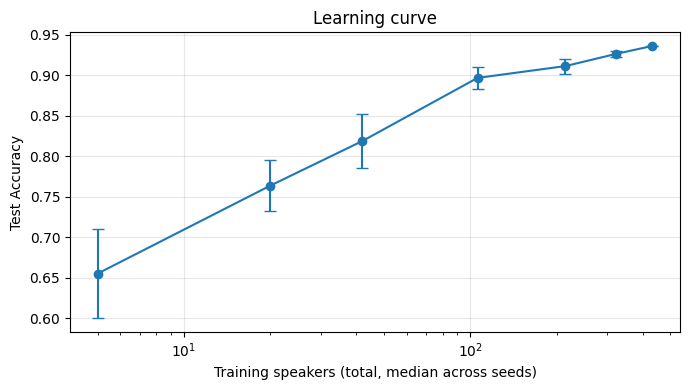

In [44]:
#Plot the learning curve
#Mean test accuracy over the ten seeds, error bars are one standard deviation
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    summary["n_speakers"],
    summary["acc_mean"],
    yerr=summary["acc_std"],
    marker="o",
    capsize=4,
)
ax.set_xscale("log")
ax.set_xlabel("Training speakers (total, median across seeds)")
ax.set_ylabel("Test Accuracy")
ax.set_title("Learning curve")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

lang       afr    eng    nl   nso   xho
fraction                               
0.01      52.3   99.7  80.4  43.2  54.9
0.05      71.8   99.1  98.4  34.9  82.2
0.10      76.7   99.9  99.4  50.8  86.1
0.25      80.5   99.9  99.7  80.1  89.6
0.50      81.4  100.0  99.7  85.6  90.0
0.75      82.7  100.0  99.8  90.4  90.9
1.00      84.1  100.0  99.8  92.6  92.2


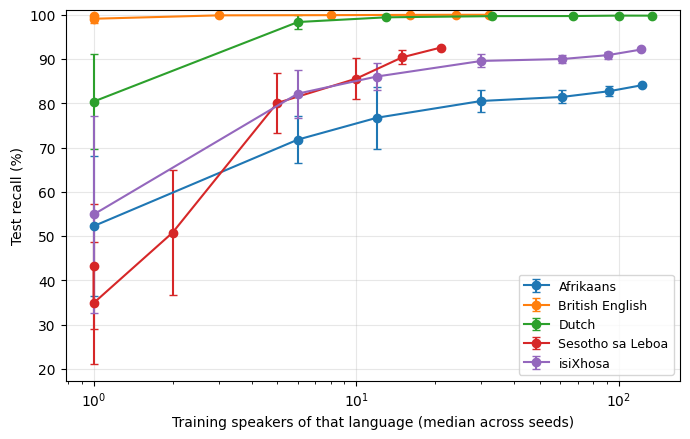

% Afrikaans
\addplot coordinates { (1,52.3) +- (0,15.8) (6,71.8) +- (0,5.4) (12,76.7) +- (0,7.0) (30,80.5) +- (0,2.5) (61,81.4) +- (0,1.5) (92,82.7) +- (0,1.1) (123,84.1) +- (0,0.0) };

% British English
\addplot coordinates { (1,99.7) +- (0,0.3) (1,99.1) +- (0,0.9) (3,99.9) +- (0,0.1) (8,99.9) +- (0,0.1) (16,100.0) +- (0,0.0) (24,100.0) +- (0,0.0) (32,100.0) +- (0,0.0) };

% Dutch
\addplot coordinates { (1,80.4) +- (0,10.8) (6,98.4) +- (0,1.6) (13,99.4) +- (0,0.2) (33,99.7) +- (0,0.1) (67,99.7) +- (0,0.1) (100,99.8) +- (0,0.1) (134,99.8) +- (0,0.0) };

% Sesotho sa Leboa
\addplot coordinates { (1,43.2) +- (0,14.1) (1,34.9) +- (0,13.7) (2,50.8) +- (0,14.2) (5,80.1) +- (0,6.8) (10,85.6) +- (0,4.7) (15,90.4) +- (0,1.6) (21,92.6) +- (0,0.0) };

% isiXhosa
\addplot coordinates { (1,54.9) +- (0,22.3) (6,82.2) +- (0,5.4) (12,86.1) +- (0,3.1) (30,89.6) +- (0,1.5) (61,90.0) +- (0,1.0) (91,90.9) +- (0,0.8) (122,92.2) +- (0,0.0) };



In [45]:
#Per-language test recall vs number of training speakers
LANG_NAMES = {"afr": "Afrikaans", "eng": "British English", "nl": "Dutch",
              "nso": "Sesotho sa Leboa", "xho": "isiXhosa"}

# Mean/std of recall and median number of speakers *of that language*, per fraction
per_lang = []
for lang in langs:
    g = clean_df.groupby("fraction").agg(
        speakers=(f"speakers_{lang}", "median"),
        recall_mean=(f"test_recall_{lang}", "mean"),
        recall_std=(f"test_recall_{lang}", "std"),
    ).reset_index()
    g["lang"] = lang
    per_lang.append(g)
per_lang = pd.concat(per_lang, ignore_index=True).sort_values(["lang", "speakers"])
per_lang[["recall_mean", "recall_std"]] *= 100          # report in percent

# Table to check the plot against
print(per_lang.pivot(index="fraction", columns="lang", values="recall_mean").round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
for lang, g in per_lang.groupby("lang"):
    ax.errorbar(g["speakers"], g["recall_mean"], yerr=g["recall_std"],
                marker="o", capsize=3, label=LANG_NAMES[lang])
ax.set_xscale("log")
ax.set_xlabel("Training speakers of that language (median across seeds)")
ax.set_ylabel("Test recall (%)")
ax.set_ylim(top=101)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Coordinates in pgfplots format, to match the style of your other figures
for lang, g in per_lang.groupby("lang"):
    coords = " ".join(f"({s:g},{m:.1f}) +- (0,{e:.1f})"
                      for s, m, e in zip(g["speakers"], g["recall_mean"], g["recall_std"].fillna(0)))
    print(f"% {LANG_NAMES[lang]}\n\\addplot coordinates {{ {coords} }};\n")